# 01 — Exploración inicial

**Proyecto:** Análisis de Elasticidad de Demanda en Delivery de Comida (v2)
**Fase:** 1 — Exploración inicial

Objetivos de este notebook:
1. Cargar las 3 tablas (train, meal_info, fulfilment_center_info)
2. Verificar el merge entre ellas (sin generar nulos inesperados)
3. EDA descriptivo: distribución de `num_orders`, `checkout_price`, `base_price`
4. Decidir alcance final antes de pasar a limpieza (Fase 2)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

RAW_DIR = '../data/raw'

## 1. Carga de datos

In [2]:
train = pd.read_csv(f'{RAW_DIR}/train.csv')
meal_info = pd.read_csv(f'{RAW_DIR}/meal_info.csv')
centers = pd.read_csv(f'{RAW_DIR}/fulfilment_center_info.csv')

print('train:', train.shape)
print('meal_info:', meal_info.shape)
print('centers:', centers.shape)

train: (456548, 9)
meal_info: (51, 3)
centers: (77, 5)


In [3]:
train.head()

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40


In [4]:
meal_info.head()

,meal_id,category,cuisine
0,1885,Beverages,Thai
1,1993,Beverages,Thai
2,2539,Beverages,Thai
3,1248,Beverages,Indian
4,2631,Beverages,Indian


In [5]:
centers.head()

,center_id,city_code,region_code,center_type,op_area
0,11,679,56,TYPE_A,3.7
1,13,590,56,TYPE_B,6.7
2,124,590,56,TYPE_C,4.0
3,66,648,34,TYPE_A,4.1
4,94,632,34,TYPE_C,3.6


## 2. Merge de las tres tablas

`train` se relaciona con `meal_info` por `meal_id` y con `centers` por `center_id`.
Verificamos ANTES y DESPUÉS del merge que el número de filas no cambie
(si aumenta, hay duplicados en alguna tabla de referencia; si disminuye, hay
IDs en train que no matchean).

In [6]:
n_rows_antes = train.shape[0]

df = train.merge(meal_info, on='meal_id', how='left') \
          .merge(centers, on='center_id', how='left')

print('Filas antes del merge :', n_rows_antes)
print('Filas después del merge:', df.shape[0])
assert df.shape[0] == n_rows_antes, 'El merge cambió el número de filas — revisar duplicados en meal_info/centers'

Filas antes del merge : 456548
Filas después del merge: 456548


## 3. Verificación de nulos post-merge

In [7]:
nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)

resumen_nulos = pd.DataFrame({'nulos': nulos, 'pct': nulos_pct})
resumen_nulos[resumen_nulos['nulos'] > 0].sort_values('nulos', ascending=False)

,nulos,pct


## 4. Tipos de datos y estadística descriptiva

In [8]:
df.dtypes

id                         int64
week                       int64
center_id                  int64
meal_id                    int64
checkout_price           float64
base_price               float64
emailer_for_promotion      int64
homepage_featured          int64
num_orders                 int64
category                     str
cuisine                      str
city_code                  int64
region_code                int64
center_type                  str
op_area                  float64
dtype: object

In [9]:
df[['checkout_price', 'base_price', 'num_orders']].describe()

,checkout_price,base_price,num_orders
count,456548.000000,456548.000000,456548.000000
mean,332.238933,354.156627,261.872760
std,152.939723,160.715914,395.922798
min,2.970000,55.350000,13.000000
25%,228.950000,243.500000,54.000000
50%,296.820000,310.460000,136.000000
75%,445.230000,458.870000,324.000000
max,866.270000,866.270000,24299.000000


## 5. Distribución de la variable dependiente (`num_orders`)

Nota de rendimiento: con ~273k filas, usamos una muestra para el histograma
de dispersión (el cálculo estadístico sí usa el dataset completo más adelante).

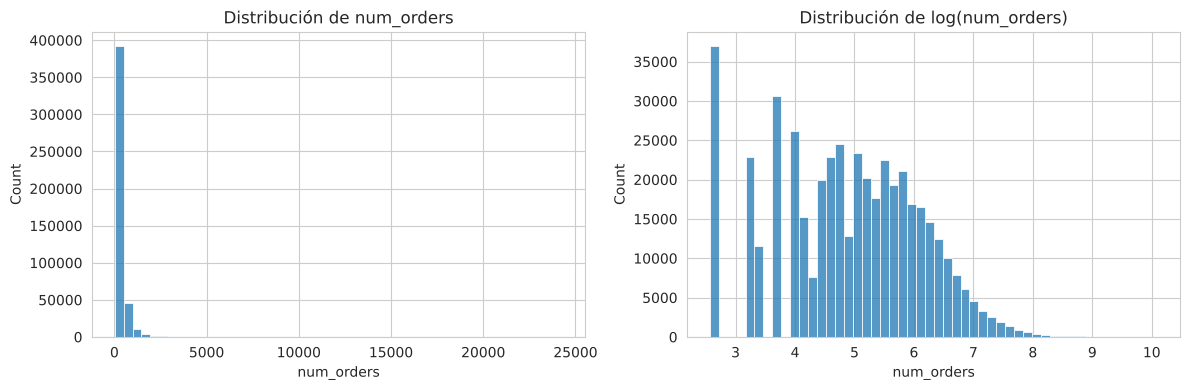

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['num_orders'], bins=50, ax=axes[0])
axes[0].set_title('Distribución de num_orders')

sns.histplot(np.log(df['num_orders']), bins=50, ax=axes[1])
axes[1].set_title('Distribución de log(num_orders)')

plt.tight_layout()
plt.show()

## 6. Relación preliminar precio-demanda (muestreada, solo para inspección visual)

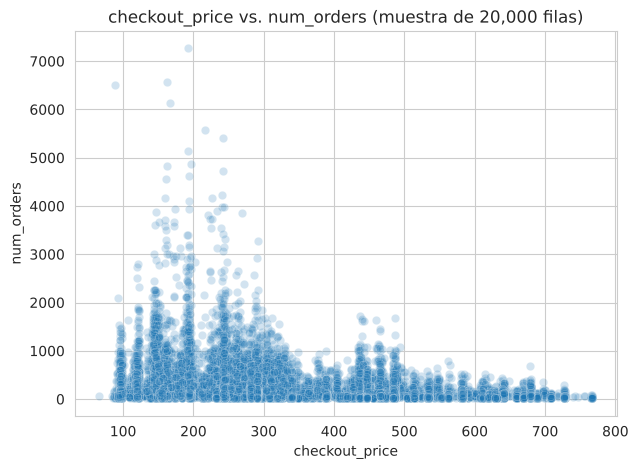

In [11]:
muestra = df.sample(n=20000, random_state=42)

plt.figure(figsize=(7, 5))
sns.scatterplot(data=muestra, x='checkout_price', y='num_orders', alpha=0.2)
plt.title('checkout_price vs. num_orders (muestra de 20,000 filas)')
plt.show()

## 7. Decisión de alcance

Confirmado: se trabaja con el **dataset completo** (todos los centros, comidas y semanas).

## Próximos pasos (Fase 2 — limpieza)
- [ ] Tratar nulos si aparecieron en la sección 3
- [ ] Construir `descuento = base_price - checkout_price` y `descuento_pct`
- [ ] Transformación log de precio y cantidad
- [ ] Guardar dataset limpio en `data/processed/`